Inicialización de sesión de Spark

In [46]:
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline
from pyspark.sql.types import IntegerType, FloatType, DoubleType, LongType
import math

In [47]:
# Inicialización manual de la sesión de Spark
spark = SparkSession.builder \
    .appName("Practica_HDFS_Spark_SQL_MLlib") \
    .master("local[*]") \
    .getOrCreate()

# Prueba de funcionamiento generando un DataFrame de 10 filas
print("Spark funcionando correctamente")
spark.range(10).show()

Spark funcionando correctamente
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
|  5|
|  6|
|  7|
|  8|
|  9|
+---+



Carga de csv desde HDFS

In [48]:
df = spark.read.csv(
    "hdfs://namenode:9000/cesar/synthetic_fraud_dataset_trunc.csv",
    header=True,
    inferSchema=True
)
df.show()
df.printSchema()

+--------------+-------+-----------+----------------+-----------------+-------+----+-----------------+-------------+--------+
|transaction_id|user_id|     amount|transaction_type|merchant_category|country|hour|device_risk_score|ip_risk_score|is_fraud|
+--------------+-------+-----------+----------------+-----------------+-------+----+-----------------+-------------+--------+
|          9608|    363|4922.587542|             ATM|           Travel|     TR|  12|      0.992346524|  0.947907677|       1|
|           456|    692|48.01830286|              QR|             Food|     US|  21|      0.168571239|  0.224057403|       0|
|          4747|    587|  136.88196|          Online|           Travel|     TR|  14|      0.296127249|  0.125057692|       0|
|          6934|    445|80.53471896|             POS|         Clothing|     TR|  23|      0.124800978|  0.159242505|       0|
|          1646|    729|120.0411582|          Online|          Grocery|     FR|  16|      0.098128954|  0.027541969|  

In [49]:

df.summary().show()

# df.select(F.percentile_approx("amount",0.5).alias("mediana")).show()

null_counts = [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]
print("--- VALORES NULOS POR COLUMNA ---")
df.select(null_counts).show()

+-------+------------------+------------------+------------------+----------------+-----------------+-------+------------------+-------------------+-------------------+-------------------+
|summary|    transaction_id|           user_id|            amount|transaction_type|merchant_category|country|              hour|  device_risk_score|      ip_risk_score|           is_fraud|
+-------+------------------+------------------+------------------+----------------+-----------------+-------+------------------+-------------------+-------------------+-------------------+
|  count|              2000|              2000|              2000|            2000|             2000|   2000|              2000|               2000|               2000|               2000|
|   mean|          4976.155|           500.952|175.78878648853825|            NULL|             NULL|   NULL|            14.209|0.17966663201150002|0.18295878603200003|              0.048|
| stddev|2873.3436428349305|286.79639778576643|478.8612

SPARK SQL

In [50]:
df.createOrReplaceTempView("Transaction_type_fraud")

spark.sql("""
    SELECT transaction_type, COUNT(*) as total_frauds
    FROM Transaction_type_fraud
    WHERE is_fraud = 1
    GROUP BY transaction_type
    ORDER BY total_frauds DESC
""").show()

+----------------+------------+
|transaction_type|total_frauds|
+----------------+------------+
|             ATM|          29|
|          Online|          25|
|              QR|          22|
|             POS|          20|
+----------------+------------+



In [51]:
# Registrar el DataFrame original una sola vez
df.createOrReplaceTempView("transactions")

# Opción A: Usando SUM y CASE WHEN (Muy explícito)
spark.sql("""
    SELECT 
        transaction_type,
        COUNT(*) as total_trxn,
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) as total_frauds,
        (SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*)) as percentage_fraud
    FROM transactions
    GROUP BY transaction_type
    ORDER BY percentage_fraud DESC
""").show()

+----------------+----------+------------+----------------+
|transaction_type|total_trxn|total_frauds|percentage_fraud|
+----------------+----------+------------+----------------+
|             ATM|       493|          29|5.88235294117647|
|          Online|       489|          25|5.11247443762781|
|              QR|       481|          22|4.57380457380457|
|             POS|       537|          20|3.72439478584730|
+----------------+----------+------------+----------------+



EDA limpieza de datos

In [52]:
# Eliminación de columnas identificadoras para evitar confusión del modelo de regresión logística al ser campos numéricos

columnas_id = [col for col in df.columns if col.lower().endswith('_id')]

df_limpio = df.drop(*columnas_id)

# df_limpio.show()

# Aplicación de transformación cíclica del campo hour para indicarle al modelo que se trata de horas y no de variables enteras

# 1. Definiendo el periodo del clico (24 horas en un día)

horas_en_un_dia = 24.0

# 2. Aplicando la transformación seno y coseno
df_ciclico = df_limpio.withColumn(
    "hour_sin",
    F.sin(2 * math.pi * F.col("hour") / horas_en_un_dia)
).withColumn(
    "hour_cos",
    F.cos(2 * math.pi * F.col("hour") / horas_en_un_dia)
)

# 3. Eliminando opcionalmente la columna hour
df_ciclico = df_ciclico.drop("hour")

# Motrando resultado para verificar nuevas columnas
df_ciclico.show()



+-----------+----------------+-----------------+-------+-----------------+-------------+--------+--------------------+--------------------+
|     amount|transaction_type|merchant_category|country|device_risk_score|ip_risk_score|is_fraud|            hour_sin|            hour_cos|
+-----------+----------------+-----------------+-------+-----------------+-------------+--------+--------------------+--------------------+
|4922.587542|             ATM|           Travel|     TR|      0.992346524|  0.947907677|       1|1.224646799147353...|                -1.0|
|48.01830286|              QR|             Food|     US|      0.168571239|  0.224057403|       0| -0.7071067811865477|  0.7071067811865474|
|  136.88196|          Online|           Travel|     TR|      0.296127249|  0.125057692|       0| -0.4999999999999997| -0.8660254037844388|
|80.53471896|             POS|         Clothing|     TR|      0.124800978|  0.159242505|       0|-0.25881904510252157|  0.9659258262890681|
|120.0411582|       

EDA estadísticas

In [53]:
print("-" * 50)
print("Cálculo de asimetría (Skewness)")
print("-" * 50)

# Generando lista de columnas a evaluar su sesgo para determinar si se aplicará algún tratamiento, excluyendo hour_sin y hour_cos ya que estas son las horas
numeric_cols = [field.name for field in df_ciclico.schema if isinstance(field.dataType, (IntegerType, FloatType, DoubleType, LongType)) and field.name not in ["hour_sin", "hour_cos", "is_fraud"]]

# expresiones_sesgo = [F.skewness(F.col(var)).alias(f"skew_{var}") for var in numeric_cols] -> solo en caso de imprimir de forma legible los sesgos
# df_ciclico.select(expresiones_sesgo).show()

skew_exprs = [F.skewness(c).alias(c) for c in numeric_cols]
skew_df = df_ciclico.select(skew_exprs)

skew_values = skew_df.first().asDict()

transformed_count = 0
details = []

# Aplicando transformación logarítmica a aquellas variables que tienen un sesgo pronunciado a la derecha.
for col_name, skew_val in skew_values.items():
    if skew_val is not None and skew_val > 1:
        df_ciclico = df_ciclico.withColumn(col_name, F.log1p(F.col(col_name)))
        transformed_count += 1
        details.append(f"'{col_name}' ({skew_val:.2f})")

if transformed_count > 0:
    print(f"Se aplicó transformación logarítmica a {transformed_count} variables cuyo skewness fue de { ', '.join(details)}.")
else:
    print("Ninguna variable numérica superó el umbral de skewness > 1 (por lo que no se requirió transformación logarítmica.")

df_ciclico.show()


--------------------------------------------------
Cálculo de asimetría (Skewness)
--------------------------------------------------
Se aplicó transformación logarítmica a 3 variables cuyo skewness fue de 'amount' (7.77), 'device_risk_score' (2.83), 'ip_risk_score' (2.79).
+------------------+----------------+-----------------+-------+-------------------+--------------------+--------+--------------------+--------------------+
|            amount|transaction_type|merchant_category|country|  device_risk_score|       ip_risk_score|is_fraud|            hour_sin|            hour_cos|
+------------------+----------------+-----------------+-------+-------------------+--------------------+--------+--------------------+--------------------+
|  8.50179271897053|             ATM|           Travel|     TR| 0.6893131018648228|  0.6667558103600584|       1|1.224646799147353...|                -1.0|
| 3.892193756121604|              QR|             Food|     US|0.15578183933439035| 0.202171080866280

CALCULO DEL VIF PARA EVITAR MULTICOLINEALIDAD CON ESCALAMIENTO DE VARIABLES

In [58]:
# Calculo de VIF
from pyspark.ml.feature import VectorAssembler, StringIndexer, OneHotEncoder
from pyspark.ml.stat import Correlation
from pyspark.ml import Pipeline
from pyspark.ml.feature import StandardScaler
import numpy as np
import pandas as pd

# La variable categórica transaction_type es fundamental para el análisis que vamos a realizar por lo que realizaremos el proceso de one-hot encoding
# 1. Convertir las categorías de texto a índices numéricos (se agregó la totalidad de las columnas categóricas de df_ciclico ya que pueden aportar valor para identificar fraudes siendo el tipo de transacción, mercancía y país la información que puede diferenciar de una transacción que no es fraude de otra que sí lo es.
# indexer = StringIndexer(inputCols=["transaction_type", "merchant_category", "country"], outputCols=["trxn_type_index", "merchant_category_index", "country_index"]) # Se retira la columna "country" ya que se identificó que genera multicolinealidad gracias al VIF
indexer = StringIndexer(inputCols=["transaction_type", "merchant_category"], outputCols=["trxn_type_index", "merchant_category_index"])

# 2. Aplicar el One-Hot Encoding sobre el índice
# encoder = OneHotEncoder(inputCols=["trxn_type_index", "merchant_category_index", "country_index"], outputCols=["trxn_type_vec", "merchant_category_vec", "country_vec"], dropLast=True)
encoder = OneHotEncoder(inputCols=["trxn_type_index", "merchant_category_index"], outputCols=["trxn_type_vec", "merchant_category_vec"], dropLast=True)

# 3. Ensamblar TODAS tus variables predictoras (el One-Hot y las numéricas)
assembler = VectorAssembler(
    # inputCols=numeric_cols + ["hour_sin", "hour_cos", "trxn_type_vec", "merchant_category_vec", "country_vec"],
    inputCols=numeric_cols + ["hour_sin", "hour_cos", "trxn_type_vec", "merchant_category_vec"],
    outputCol="features"
)

# 4. Escalamiento de variables
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=False,
    withStd=True
)

# 5. Evaluación de multicolinealidad VIF
# 5.1 Aplicar las transformaciones temporales para generar la columna features

# ----------------------------------------------------------------------
# Encadenamiento manual de acciones (Es mejor utilizar el Pipeline)
# Paso A: Generar las columnas *_index sobre df_ciclico
# df_temp = indexer.fit(df_ciclico).transform(df_ciclico)
# Paso B: Generar las columnas *_vec usando el df_temp que YA contiene las columnas *_index
# df_temp = encoder.fit(df_temp).transform(df_temp)
# Paso C: Generar la columna features ensamblando todo sobre el df_temp acumulado
# df_temp = assembler.transform(df_temp)
# ----------------------------------------------------------------------

# Pipeline de acciones
# Paso A: Definir la secuencia de procesamiento
pipeline = Pipeline(stages=[indexer, encoder, assembler, scaler])
# Paso B: Ajustar y transformar en un solo paso limpio
df_temp = pipeline.fit(df_ciclico).transform(df_ciclico)

# 5.2 Calcular la Matriz de correlación de Pearson sobre el vector ensamblado
print("Calculando matriz de correlación en Spark...")
matriz_corr = Correlation.corr(df_temp, "features").head()[0].toArray()

# 5.3 Calcular la matriz inversa usando álgebra lineal de NumPy
matriz_inversa = np.linalg.inv(matriz_corr)

# 5.4 Extraer la diagonal principal (que corresponde matemáticamente al VIF)
valores_vif = np.diagonal(matriz_inversa)

# 5.5 Extraer los nombres reales de las variables desde los metadatos de Spark
meta = df_temp.schema["features"].metadata["ml_attr"]["attrs"]
nombres_features = []

# PySpark clasifica los metadatos en 'numeric' (numéricas) y 'binary' (one-hot)
for attr_type in ["numeric", "binary"]:
    if attr_type in meta:
        for attr in meta[attr_type]:
            nombres_features.append((attr["idx"], attr["name"]))

# Ordenar por el índice original para que coincida exactamente con los valores VIF
nombres_features.sort(key=lambda x: x[0])
nombres_limpios = [nombre for idx, nombre in nombres_features]

# 5.6 Mostrar el resultado ordenado en un DataFrame de Pandas para fácil lectura
vif_df = pd.DataFrame({
    "Variable": nombres_limpios,
    "VIF": valores_vif
})

print("-" * 40)
print("ANALISIS VIF (Factor de Inflación de Varianza)")
print("-" * 40)
print(vif_df.sort_values(by="VIF", ascending=False).to_string(index=False))


Calculando matriz de correlación en Spark...
----------------------------------------
ANALISIS VIF (Factor de Inflación de Varianza)
----------------------------------------
                         Variable      VIF
                device_risk_score 1.829010
                    ip_risk_score 1.817938
       merchant_category_vec_Food 1.705293
    merchant_category_vec_Grocery 1.697860
   merchant_category_vec_Clothing 1.678174
merchant_category_vec_Electronics 1.644783
                trxn_type_vec_POS 1.558791
                trxn_type_vec_ATM 1.534804
             trxn_type_vec_Online 1.530774
                           amount 1.134806
                         hour_sin 1.099932
                         hour_cos 1.099442


In [59]:
import pyspark.sql.functions as F
# Fase 1: Cálculo de Pesos por Clase
# 1.1 Contamos cuántas transacciones hay de cada tipo para calcular los pesos
total_trx = df_ciclico.count()
fraudes = df_ciclico.filter(F.col("is_fraud") == 1).count()
legitimas = total_trx - fraudes

# 1.2 Fórmula estadística estándar para balanceo de pesos: N / (2 * count)
peso_fraude = total_trx / (2 * fraudes)
peso_legitimas = total_trx / (2 * legitimas)

# 1.3 Agregamos la columna de pesos al DF antes de meterlo al Pipleline
df_pesos = df_ciclico.withColumn(
    "class_weight",
    F.when(F.col("is_fraud") == 1, peso_fraude).otherwise(peso_legitimas)
)

# Fase 2: División Segura de Datos (Train/Test Split)
train, test = df_pesos.randomSplit([0.8, 0.2], seed=42)

# Fase 3: Modelo de regresión logística y Pipeline
# 3.1 Configuramos la regresión apuntando a las columnas correctas, incluyendo los pesos
lr = LogisticRegression(
    featuresCol="scaled_features",
    labelCol="is_fraud",
    weightCol="class_weight"
)

# 3.2 Creación del Pipeline
pipeline_final = Pipeline(stages=[indexer, encoder, assembler, scaler, lr])

# Fase 4. Entrenamiento y Predicción
# 4.1 Entrenamos todo el flujo (desde la indexación hasta la regresión)
modelo_final = pipeline_final.fit(train)

# 4.2 Generamos predicciones usando los datos del test que nunca han sido vistos
predicciones = modelo_final.transform(test)

# 4.3 Ver resultados (seleccionando columnas clave para no ver toda la tabla)
predicciones.select("transaction_type", "amount", "class_weight", "is_fraud", "probability", "prediction").show()

+----------------+------------------+------------------+--------+--------------------+----------+
|transaction_type|            amount|      class_weight|is_fraud|         probability|prediction|
+----------------+------------------+------------------+--------+--------------------+----------+
|             ATM|0.6931471805599453|0.5252100840336135|       0|[0.99999999999920...|       0.0|
|             ATM|0.6931471805599453|0.5252100840336135|       0|[0.99999999999999...|       0.0|
|             ATM|0.6931471805599453|0.5252100840336135|       0|[0.99999999999996...|       0.0|
|             ATM|0.6931471805599453|0.5252100840336135|       0|[0.99999999999999...|       0.0|
|          Online|0.6931471805599453|0.5252100840336135|       0|[0.99999999345343...|       0.0|
|          Online|0.6931471805599453|0.5252100840336135|       0|[0.99999999996671...|       0.0|
|             POS|0.6931471805599453|0.5252100840336135|       0|[0.99999999999889...|       0.0|
|             POS|0.

In [60]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# 1. Instanciamos el evaluador indicando las columnas
evaluador_roc = BinaryClassificationEvaluator(
    rawPredictionCol="rawPrediction",
    labelCol="is_fraud",
    metricName="areaUnderROC"
)

# 2. Calculamos el AUC sobre nuestro set de prueba
auc_roc = evaluador_roc.evaluate(predicciones)

print(f"El Área Bajo la Curva ROC (AUC-ROC) es: {auc_roc:.4f}")

El Área Bajo la Curva ROC (AUC-ROC) es: 1.0000


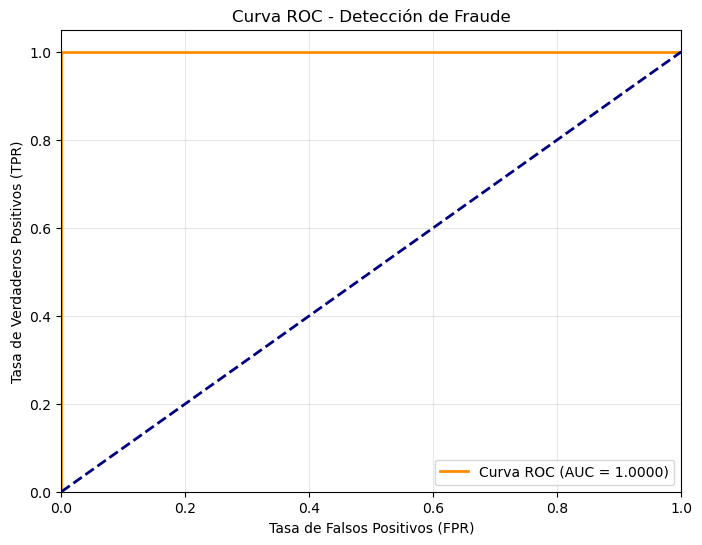

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from pyspark.ml.functions import vector_to_array
import pandas as pd

# 1. Extraer la probabilidad de fraude (clase 1) del vector de probabilidad
# PySpark guarda las probabilidades como un vector [prob_0, prob_1]
preds_df = predicciones.withColumn("prob_fraude", vector_to_array("probability")[1])

# 2. Llevar los resultados de evaluación a Pandas para graficar
pd_preds = preds_df.select("is_fraud", "prob_fraude").toPandas()

# 3. Calcular Tasa de Falsos Positivos (FPR) y Tasa de Verdaderos Positivos (TPR)
fpr, tpr, umbrales = roc_curve(pd_preds["is_fraud"], pd_preds["prob_fraude"])
roc_auc = auc(fpr, tpr)

# 4. Construir el gráfico con Matplotlib
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Línea de modelo aleatorio
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Detección de Fraude')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [63]:
import pandas as pd

# 1. Extraer el modelo de Regresión Logística (última etapa del pipeline)
lr_modelo = modelo_final.stages[-1]

# 2. Extraer los coeficientes matemáticos y la intersección (intercept)
pesos = lr_modelo.coefficients.toArray()

# 3. Recuperar exactamente la lista de nombres de variables que metimos al ensamblador
# Recuerda que usamos numeric_cols + ['hour_sin', 'hour_cos', 'trxn_type_vec', 'merchant_category_vec']
# Nota: Para las columnas de One-Hot Encoding, Spark expande los nombres automáticamente.
# Una forma segura de listar los features es combinarlas:
nombres_features = numeric_cols + ['hour_sin', 'hour_cos']

# 4. Crear un DataFrame de Pandas para visualizar el peso de cada variable
pesos_df = pd.DataFrame({
    "Variable": nombres_features[:len(pesos)], # Ajustamos al tamaño del arreglo de coeficientes
    "Peso (Coeficiente)": pesos[:len(nombres_features)],
    "Impacto Absoluto": [abs(p) for p in pesos[:len(nombres_features)]]
}).sort_values(by="Impacto Absoluto", ascending=False)

print("-" * 50)
print("PESOS PREDICTIVOS DEL MODELO DE REGRESIÓN")
print("-" * 50)
print(pesos_df.to_string(index=False))
print(f"\nIntercepto del modelo: {lr_modelo.intercept:.4f}")

--------------------------------------------------
PESOS PREDICTIVOS DEL MODELO DE REGRESIÓN
--------------------------------------------------
         Variable  Peso (Coeficiente)  Impacto Absoluto
    ip_risk_score            6.406652          6.406652
device_risk_score            6.022589          6.022589
           amount            0.594722          0.594722
         hour_sin           -0.475639          0.475639
         hour_cos           -0.225474          0.225474

Intercepto del modelo: -41.6197


CREACION DE UN NUEVO MODELO EXCLUYENDO LAS VARIABLES QUE ESTAN GENERANDO SOBRE AJUSTE

In [64]:
from pyspark.ml.feature import VectorAssembler, StringIndexer, OneHotEncoder, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline
from pyspark.sql.types import IntegerType, FloatType, DoubleType, LongType
import pyspark.sql.functions as F

# 1. Definir nuevamente tus columnas numéricas puras (excluyendo los risk scores)
# Aquí filtramos las que no sean identificadores, ni de hora, ni etiquetas, ni de riesgo
numeric_cols = [
    field.name for field in df_ciclico.schema 
    if isinstance(field.dataType, (IntegerType, FloatType, DoubleType, LongType)) 
    and field.name not in ["hour_sin", "hour_cos", "is_fraud", "ip_risk_score", "device_risk_score"]
]

print("Variables numéricas seleccionadas para el modelo:", numeric_cols)

# 2. Configurar etapas del Pipeline
indexer = StringIndexer(inputCols=["transaction_type", "merchant_category"], outputCols=["trxn_type_index", "merchant_category_index"])
encoder = OneHotEncoder(inputCols=["trxn_type_index", "merchant_category_index"], outputCols=["trxn_type_vec", "merchant_category_vec"], dropLast=True)

# Ensamblar solo con amount, hour_sin, hour_cos y las categóricas codificadas
assembler = VectorAssembler(
    inputCols=numeric_cols + ["hour_sin", "hour_cos", "trxn_type_vec", "merchant_category_vec"],
    outputCol="features"
)

# Escalamiento general
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=False,
    withStd=True
)

# 3. Cálculo de Pesos por Clase (Balanceo por desbalance de fraude)
total_trx = df_ciclico.count()
fraudes = df_ciclico.filter(F.col("is_fraud") == 1).count()
legitimas = total_trx - fraudes

peso_fraude = total_trx / (2 * fraudes)
peso_legitimo = total_trx / (2 * legitimas)

df_pesos = df_ciclico.withColumn(
    "class_weight",
    F.when(F.col("is_fraud") == 1, peso_fraude).otherwise(peso_legitimo)
)

# 4. División Segura (Train / Test Split)
train, test = df_pesos.randomSplit([0.8, 0.2], seed=42)

# 5. Modelo de Regresión Logística con Pesos
lr = LogisticRegression(
    featuresCol="scaled_features", 
    labelCol="is_fraud",
    weightCol="class_weight"
)

# 6. Construir y Entrenar el Pipeline Completo
pipeline_final = Pipeline(stages=[indexer, encoder, assembler, scaler, lr])
modelo_final = pipeline_final.fit(train)

# 7. Evaluar y Transformar el set de prueba
predicciones = modelo_final.transform(test)

print("¡Modelo entrenado exitosamente sin variables de riesgo!")

Variables numéricas seleccionadas para el modelo: ['amount']
¡Modelo entrenado exitosamente sin variables de riesgo!


El Área Bajo la Curva ROC (AUC-ROC) es: 0.9620


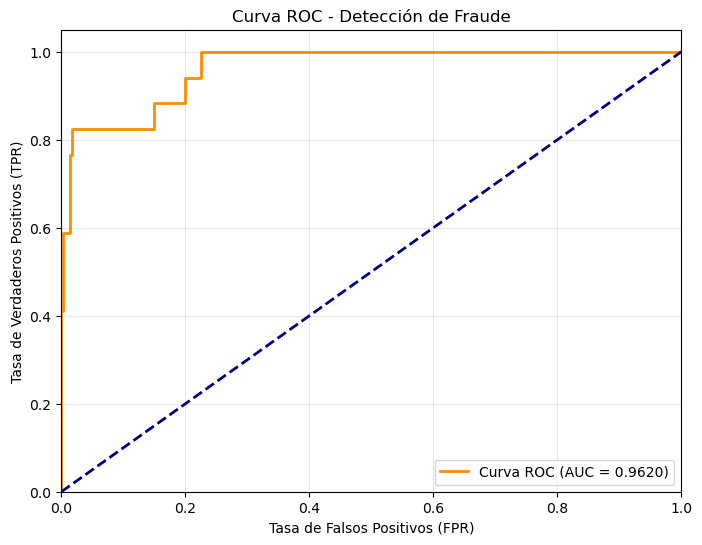

In [66]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# 1. Instanciamos el evaluador indicando las columnas
evaluador_roc = BinaryClassificationEvaluator(
    rawPredictionCol="rawPrediction",
    labelCol="is_fraud",
    metricName="areaUnderROC"
)

# 2. Calculamos el AUC sobre nuestro set de prueba
auc_roc = evaluador_roc.evaluate(predicciones)

print(f"El Área Bajo la Curva ROC (AUC-ROC) es: {auc_roc:.4f}")

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from pyspark.ml.functions import vector_to_array
import pandas as pd

# 1. Extraer la probabilidad de fraude (clase 1) del vector de probabilidad
# PySpark guarda las probabilidades como un vector [prob_0, prob_1]
preds_df = predicciones.withColumn("prob_fraude", vector_to_array("probability")[1])

# 2. Llevar los resultados de evaluación a Pandas para graficar
pd_preds = preds_df.select("is_fraud", "prob_fraude").toPandas()

# 3. Calcular Tasa de Falsos Positivos (FPR) y Tasa de Verdaderos Positivos (TPR)
fpr, tpr, umbrales = roc_curve(pd_preds["is_fraud"], pd_preds["prob_fraude"])
roc_auc = auc(fpr, tpr)

# 4. Construir el gráfico con Matplotlib
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Línea de modelo aleatorio
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Detección de Fraude')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

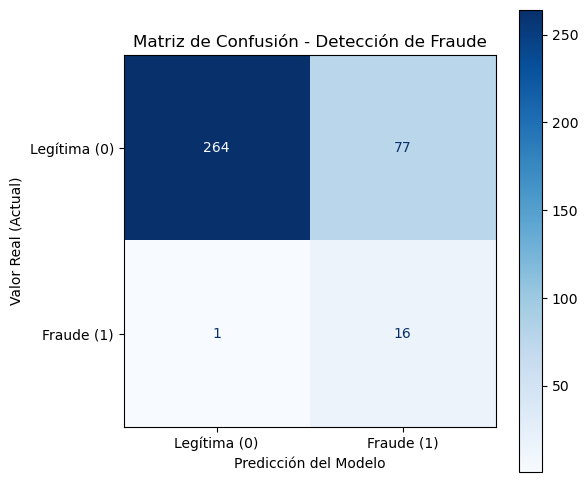

----------------------------------------
DESGLOSE DE LA MATRIZ DE CONFUSIÓN
----------------------------------------
Verdaderos Negativos (TN - Aciertos Legítimos): 264
Falsos Positivos (FP - Falsas Alarmas): 77
Falsos Negativos (FN - Fraudes no detectados): 1
Verdaderos Positivos (TP - Fraudes atrapados): 16


In [67]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Extraer las columnas de valores reales y predicciones al nodo driver con Pandas
df_confusion = predicciones.select("is_fraud", "prediction").toPandas()

# 2. Calcular la matriz de confusión usando scikit-learn
cm = confusion_matrix(df_confusion["is_fraud"], df_confusion["prediction"])

# 3. Graficar la matriz de confusión de manera visual y atractiva
plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Legítima (0)", "Fraude (1)"])
disp.plot(cmap=plt.cm.Blues, values_format='g', ax=plt.gca())
plt.title("Matriz de Confusión - Detección de Fraude")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real (Actual)")
plt.grid(False) # Desactivar rejilla para mejor lectura visual
plt.show()

# 4. Imprimir los valores numéricos exactos en consola
tn, fp, fn, tp = cm.ravel()
print("-" * 40)
print("DESGLOSE DE LA MATRIZ DE CONFUSIÓN")
print("-" * 40)
print(f"Verdaderos Negativos (TN - Aciertos Legítimos): {tn}")
print(f"Falsos Positivos (FP - Falsas Alarmas): {fp}")
print(f"Falsos Negativos (FN - Fraudes no detectados): {fn}")
print(f"Verdaderos Positivos (TP - Fraudes atrapados): {tp}")

In [53]:
# Cerrar sesión de Spark
spark.stop()